# Deep Neural Networks Architecture Assignment
## Member 1: Dataset Preprocessing, Tokenizer & Custom VAE

This notebook completes all responsibilities for **Development Stage 1**:
1. Download and store the raw dataset in `dataset/raw/`.
2. Center-crop and resize images to 64x64 RGB into `dataset/flickr8k/`.
3. Build a custom word tokenizer and vocabulary (`tokenizer/vocab.json`).
4. Implement a custom ConvVAE from scratch (compressing 64x64 to 16x16 latents).
5. Train the VAE with combined reconstruction loss (MSE + L1) and KL divergence.
6. Evaluate and save real vs. reconstructed image comparisons.
7. Encode and cache latent representations and pre-tokenized captions for Member 2.
8. Export `models/vae.py` for module handover.

In [14]:
# Cell 1: Environment Dependencies
%pip install -U datasets huggingface_hub pillow pandas matplotlib tqdm
%pip install -U torch torchvision
%pip install torchinfo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
# Cell 2: Imports, Seeds & Directory Setup
from pathlib import Path
import os, re, json, random, time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchinfo import summary


# Set seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Define project directory structure
PROJECT_DIR = Path(r"C:\DNN\DNN_Project")
RAW_DIR = PROJECT_DIR / "dataset" / "raw"
DATA_DIR = PROJECT_DIR / "dataset" / "flickr8k"
MODEL_DIR = PROJECT_DIR / "models"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
LATENT_DIR = PROJECT_DIR / "latents"
TOKENIZER_DIR = PROJECT_DIR / "tokenizer"
RESULTS_DIR = PROJECT_DIR / "results"

for folder in [RAW_DIR, DATA_DIR, MODEL_DIR, CHECKPOINT_DIR, LATENT_DIR, TOKENIZER_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Hardware detection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

# Global Configuration
IMAGE_SIZE = 64
LATENT_CHANNELS = 4
BATCH_SIZE = 16
NUM_WORKERS = 0  # 0 is safest on Windows
EPOCHS = 20
LEARNING_RATE = 2e-4
BETA_KL = 1e-4

PyTorch: 2.14.1+cu132
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
VRAM: 4.00 GB


### Step 1: Download Raw Dataset into `dataset/raw/`

In [4]:
from datasets import load_dataset

print(f"Downloading dataset to: {RAW_DIR}")
hf_dataset = load_dataset(
    "intro/flickr8k",
    cache_dir=str(RAW_DIR)
)
print("Download complete!")
print(hf_dataset)

Resolving data files:   0%|          | 0/6001 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1001 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1001 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/6001 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1001 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1001 [00:00<?, ?it/s]

Download complete!
DatasetDict({
    train: Dataset({
        features: ['image', 'split', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
        num_rows: 6000
    })
    dev: Dataset({
        features: ['image', 'split', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['image', 'split', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
        num_rows: 1000
    })
})


### Step 2: Preprocess & Center-Crop to 64x64 Images

In [5]:
# Cell 4: Preprocessing and Exporting 64x64 Images
def extract_image(item):
    for key in ["image", "img", "picture", "jpg"]:
        if key in item and item[key] is not None:
            val = item[key]
            if isinstance(val, Image.Image):
                return val.convert("RGB")
            if isinstance(val, dict) and val.get("bytes") is not None:
                import io
                return Image.open(io.BytesIO(val["bytes"])).convert("RGB")
            if isinstance(val, str) and os.path.exists(val):
                return Image.open(val).convert("RGB")
    raise KeyError(f"Cannot find an image in columns: {list(item.keys())}")

def extract_captions(item):
    caption_keys = sorted(
        [k for k in item if re.fullmatch(r"caption[_-]?\d+", k, re.IGNORECASE)],
        key=lambda k: int(re.search(r"\d+", k).group())
    )
    captions = [str(item[k]).strip() for k in caption_keys if item[k] and str(item[k]).strip()]
    if captions:
        return captions

    for key in ["captions", "caption", "text", "sentence"]:
        if key in item and item[key] is not None:
            val = item[key]
            if isinstance(val, str) and val.strip():
                return [val.strip()]
            if isinstance(val, (list, tuple)):
                res = [str(c).strip() for c in val if str(c).strip()]
                if res:
                    return res
    raise KeyError(f"Cannot find captions in columns: {list(item.keys())}")

def get_split_mapping(ds):
    mapping = {}
    if "train" in ds: mapping["train"] = "train"
    if "validation" in ds: mapping["validation"] = "val"
    elif "dev" in ds: mapping["dev"] = "val"
    if "test" in ds: mapping["test"] = "test"
    return mapping

split_mapping = get_split_mapping(hf_dataset)

# Export processed images
for source_split, output_split in split_mapping.items():
    split_data = hf_dataset[source_split]
    image_dir = DATA_DIR / output_split / "images"
    image_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    print(f"Exporting {source_split} -> {output_split} ({len(split_data)} images)...")

    for index, item in enumerate(tqdm(split_data)):
        raw_img = extract_image(item)
        # Center-crop then resize to 64x64 without squashing
        image = ImageOps.fit(raw_img, (IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS)
        
        image_name = f"{output_split}_{index:05d}.jpg"
        image.save(image_dir / image_name, format="JPEG", quality=95)
        captions = extract_captions(item)
        rows.append({
            "image": image_name,
            "image_id": f"{output_split}_{index:05d}",
            "captions": json.dumps(captions, ensure_ascii=False),
            "caption_count": len(captions),
        })

    output_csv = DATA_DIR / output_split / "captions.csv"
    pd.DataFrame(rows).to_csv(output_csv, index=False, encoding="utf-8")
    print(f"Saved {output_csv} ({len(rows)} rows)")

print(f"Preprocessing complete! Cleaned dataset saved at: {DATA_DIR}")

Exporting train -> train (6000 images)...


  0%|          | 0/6000 [00:00<?, ?it/s]

Saved C:\DNN\DNN_Project\dataset\flickr8k\train\captions.csv (6000 rows)
Exporting dev -> val (1000 images)...


  0%|          | 0/1000 [00:00<?, ?it/s]

Saved C:\DNN\DNN_Project\dataset\flickr8k\val\captions.csv (1000 rows)
Exporting test -> test (1000 images)...


  0%|          | 0/1000 [00:00<?, ?it/s]

Saved C:\DNN\DNN_Project\dataset\flickr8k\test\captions.csv (1000 rows)
Preprocessing complete! Cleaned dataset saved at: C:\DNN\DNN_Project\dataset\flickr8k


### Step 3: Inspect Processed Samples

,image,image_id,captions,caption_count
0,train_00000.jpg,train_00000,"[""A child in a pink dress is climbing up a set...",5
1,train_00001.jpg,train_00001,"[""A black dog and a spotted dog are fighting"",...",5
2,train_00002.jpg,train_00002,"[""A little girl covered in paint sits in front...",5
3,train_00003.jpg,train_00003,"[""A man lays on a bench while his dog sits by ...",5
4,train_00004.jpg,train_00004,"[""A man in an orange hat starring at something...",5


Training images count: 6000
Caption count distribution: {5: 6000}


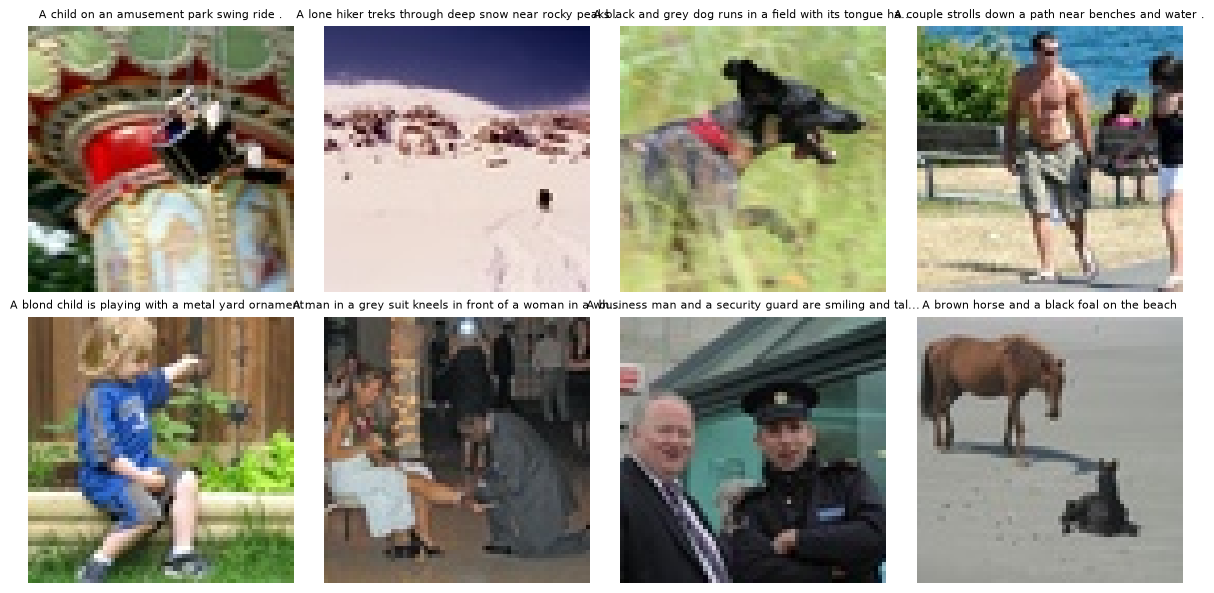

In [2]:
# Cell 5: Inspect Processed Dataset
train_csv = DATA_DIR / "train" / "captions.csv"
train_df = pd.read_csv(train_csv)
display(train_df.head())
print("Training images count:", len(train_df))
print("Caption count distribution:", train_df["caption_count"].value_counts().to_dict())

# Visualize 8 samples with captions
n = min(8, len(train_df))
sample = train_df.sample(n=n, random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    img = Image.open(DATA_DIR / "train" / "images" / row["image"]).convert("RGB")
    caption_list = json.loads(row["captions"])
    ax.imshow(img)
    cap = caption_list[0]
    ax.set_title(cap[:55] + ("..." if len(cap) > 55 else ""), fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Step 4: Custom Word Tokenizer & Vocabulary Builder

In [3]:
# Cell 6: Tokenizer Implementation
SPECIAL_TOKENS = ["<pad>", "<unk>", "<bos>", "<eos>"]
MAX_VOCAB_SIZE = 10000
MIN_WORD_FREQ = 2
MAX_TEXT_LENGTH = 40

def tokenize_text(text):
    return re.findall(r"[a-z0-9]+(?:'[a-z]+)?", str(text).lower())

word_counts = Counter()
for csv_path in DATA_DIR.glob("*/captions.csv"):
    frame = pd.read_csv(csv_path)
    for packed in frame["captions"]:
        for caption in json.loads(packed):
            word_counts.update(tokenize_text(caption))

vocab = {token: i for i, token in enumerate(SPECIAL_TOKENS)}
for word, freq in word_counts.most_common():
    if freq < MIN_WORD_FREQ or len(vocab) >= MAX_VOCAB_SIZE:
        continue
    if word not in vocab:
        vocab[word] = len(vocab)

id_to_vocab = {idx: token for token, idx in vocab.items()}

# Save vocabulary and configuration files
with open(TOKENIZER_DIR / "vocab.json", "w", encoding="utf-8") as f:
    json.dump(vocab, f, ensure_ascii=False, indent=2)

with open(TOKENIZER_DIR / "tokenizer_config.json", "w", encoding="utf-8") as f:
    json.dump({
        "max_text_length": MAX_TEXT_LENGTH,
        "special_tokens": SPECIAL_TOKENS,
        "vocab_size": len(vocab),
        "lowercase": True,
        "min_word_frequency": MIN_WORD_FREQ
    }, f, indent=2)

PAD_ID, UNK_ID, BOS_ID, EOS_ID = [vocab[t] for t in SPECIAL_TOKENS]

def encode_caption(text, max_length=MAX_TEXT_LENGTH):
    tokens = tokenize_text(text)
    ids = [BOS_ID] + [vocab.get(t, UNK_ID) for t in tokens[:max_length-2]] + [EOS_ID]
    ids = ids[:max_length]
    return ids + [PAD_ID] * (max_length - len(ids))

def decode_caption(token_ids):
    tokens = [id_to_vocab.get(int(i), "<unk>") for i in token_ids]
    return " ".join([t for t in tokens if t not in ["<pad>", "<bos>", "<eos>"]])

test_cap = json.loads(train_df.iloc[0]["captions"])[0]
test_encoded = encode_caption(test_cap)
print("Vocabulary size:", len(vocab))
print("Sample caption:", test_cap)
print("Token IDs:", test_encoded)
print("Decoded back:", decode_caption(test_encoded))
print("Saved:", TOKENIZER_DIR / "vocab.json")

Vocabulary size: 5086
Sample caption: A child in a pink dress is climbing up a set of stairs in an entry way .
Token IDs: [2, 4, 44, 5, 4, 91, 173, 8, 120, 52, 4, 404, 13, 395, 5, 29, 1, 676, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Decoded back: a child in a pink dress is climbing up a set of stairs in an <unk> way
Saved: C:\DNN\DNN_Project\tokenizer\vocab.json


### Step 5: PyTorch Dataset & DataLoader

In [4]:
# Cell 7: Dataset and DataLoader
image_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),  # Map [0, 1] to [-1, 1]
])

class FlickrImageDataset(Dataset):
    def __init__(self, split, transform=None):
        self.split = split
        self.root = DATA_DIR / split
        self.frame = pd.read_csv(self.root / "captions.csv")
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        image = Image.open(self.root / "images" / row["image"]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        captions = json.loads(row["captions"])
        # Randomly choose one of the 5 captions during training for data augmentation
        caption = random.choice(captions) if (self.split == "train" and len(captions) > 1) else captions[0]
        return image, caption, row["image_id"]

train_dataset = FlickrImageDataset("train", image_transform)
val_dataset = FlickrImageDataset("val", image_transform) if (DATA_DIR / "val" / "captions.csv").exists() else None

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()) if val_dataset else None

batch_images, batch_captions, batch_ids = next(iter(train_loader))
print("Batch Image Tensor Shape:", batch_images.shape)
print("Pixel Range:", batch_images.min().item(), "to", batch_images.max().item())
print("Sample Caption:", batch_captions[0])
print("Sample ID:", batch_ids[0])

Batch Image Tensor Shape: torch.Size([16, 3, 64, 64])
Pixel Range: -1.0 to 1.0
Sample Caption: A black and brown dog jumps through the snow .
Sample ID: train_03088


### Step 6: Custom ConvVAE Architecture (64x64 -> 16x16 Latents)

In [7]:
# Cell 8: ConvVAE Architecture
class ConvVAE(nn.Module):
    def __init__(self, latent_channels=4):
        super().__init__()
        self.latent_channels = latent_channels
        
        # Encoder: (3, 64, 64) -> (4, 16, 16) compression factor 4
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1), nn.GroupNorm(8, 64), nn.SiLU(),     # -> (64, 32, 32)
            nn.Conv2d(64, 128, 4, 2, 1), nn.GroupNorm(8, 128), nn.SiLU(),   # -> (128, 16, 16)
            nn.Conv2d(128, 256, 3, 1, 1), nn.GroupNorm(8, 256), nn.SiLU(),  # -> (256, 16, 16)
        )
        self.to_mu = nn.Conv2d(256, latent_channels, 1)
        self.to_logvar = nn.Conv2d(256, latent_channels, 1)

        # Decoder: (4, 16, 16) -> (3, 64, 64)
        self.decoder_input = nn.Sequential(
            nn.Conv2d(latent_channels, 256, 3, 1, 1),
            nn.GroupNorm(8, 256), nn.SiLU(),
        )
        self.decoder = nn.Sequential(
            nn.Conv2d(256, 128, 3, 1, 1), nn.GroupNorm(8, 128), nn.SiLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.GroupNorm(8, 64), nn.SiLU(),  # -> (64, 32, 32)
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.GroupNorm(8, 32), nn.SiLU(),   # -> (32, 64, 64)
            nn.Conv2d(32, 3, 3, 1, 1), nn.Tanh(),                                  # -> (3, 64, 64) in [-1, 1]
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.to_mu(h)
        logvar = self.to_logvar(h).clamp(-10, 10)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        return mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)

    def decode(self, z):
        return self.decoder(self.decoder_input(z))

    def forward(self, x, sample=True):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar) if sample else mu
        return self.decode(z), mu, logvar

vae = ConvVAE(latent_channels=LATENT_CHANNELS).to(device)
print(f"Trainable parameters: {sum(p.numel() for p in vae.parameters() if p.requires_grad):,}")

# Forward pass test
with torch.no_grad():
    dummy = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
    rec, mu, logvar = vae(dummy)
print("Input:", tuple(dummy.shape), "| Reconstruction:", tuple(rec.shape), "| Latent:", tuple(mu.shape))

Trainable parameters: 902,731
Input: (2, 3, 64, 64) | Reconstruction: (2, 3, 64, 64) | Latent: (2, 4, 16, 16)


In [9]:
class ConvVAE(nn.Module):
    def __init__(self, latent_channels=4):
        super().__init__()
        self.latent_channels = latent_channels

        # Encoder: (3, 64, 64) -> (256, 16, 16)
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1),
            nn.GroupNorm(8, 64),
            nn.SiLU(),

            nn.Conv2d(64, 128, 4, 2, 1),
            nn.GroupNorm(8, 128),
            nn.SiLU(),

            nn.Conv2d(128, 256, 3, 1, 1),
            nn.GroupNorm(8, 256),
            nn.SiLU(),
        )

        # Latent distribution parameters
        self.to_mu = nn.Conv2d(256, latent_channels, 1)
        self.to_logvar = nn.Conv2d(256, latent_channels, 1)

        # Decoder input: (latent_channels, 16, 16) -> (256, 16, 16)
        self.decoder_input = nn.Sequential(
            nn.Conv2d(latent_channels, 256, 3, 1, 1),
            nn.GroupNorm(8, 256),
            nn.SiLU(),
        )

        # Decoder: (256, 16, 16) -> (3, 64, 64)
        self.decoder = nn.Sequential(
            nn.Conv2d(256, 128, 3, 1, 1),
            nn.GroupNorm(8, 128),
            nn.SiLU(),

            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.GroupNorm(8, 64),
            nn.SiLU(),

            nn.ConvTranspose2d(64, 32, 4, 2, 1),
            nn.GroupNorm(8, 32),
            nn.SiLU(),

            nn.Conv2d(32, 3, 3, 1, 1),
            nn.Tanh(),
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.to_mu(h)
        logvar = self.to_logvar(h).clamp(-10, 10)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(self.decoder_input(z))

    def forward(self, x, sample=True):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar) if sample else mu
        reconstruction = self.decode(z)
        return reconstruction, mu, logvar


# --------------------------------------------------
# 1. Create the model
# --------------------------------------------------
vae = ConvVAE(latent_channels=LATENT_CHANNELS).to(device)

total_params = sum(p.numel() for p in vae.parameters())
trainable_params = sum(
    p.numel() for p in vae.parameters() if p.requires_grad
)

print("ConvVAE model created successfully.")
print(f"Device: {device}")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


# --------------------------------------------------
# 2. Test the forward pass
# --------------------------------------------------
vae.eval()

with torch.no_grad():
    dummy = torch.randn(
        2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device
    )
    reconstruction, mu, logvar = vae(dummy)

print("\nForward Pass Test")
print("Input shape:          ", tuple(dummy.shape))
print("Reconstruction shape: ", tuple(reconstruction.shape))
print("Mu shape:             ", tuple(mu.shape))
print("Logvar shape:         ", tuple(logvar.shape))

assert reconstruction.shape == dummy.shape, (
    "Error: reconstruction shape does not match input shape."
)

print("Forward pass successful!")


# --------------------------------------------------
# 3. Capture layer shapes for the Pandas table
# --------------------------------------------------
layer_rows = []
hooks = []

def get_shape(value):
    if isinstance(value, torch.Tensor):
        return str(tuple(value.shape))
    if isinstance(value, (list, tuple)):
        return ", ".join(get_shape(v) for v in value)
    return str(type(value).__name__)


def register_hook(name, module):
    # Record leaf modules only to avoid duplicate parent summaries.
    if len(list(module.children())) != 0:
        return

    def hook(module, inputs, output):
        layer_rows.append({
            "Layer": name,
            "Type": module.__class__.__name__,
            "Input Shape": get_shape(inputs),
            "Output Shape": get_shape(output),
            "Parameters": sum(p.numel() for p in module.parameters()),
            "Trainable": any(p.requires_grad for p in module.parameters()),
        })

    hooks.append(module.register_forward_hook(hook))


for name, module in vae.named_modules():
    if name:
        register_hook(name, module)


# Run a fresh forward pass to collect shapes
layer_rows.clear()
vae.eval()

with torch.no_grad():
    _ = vae(torch.randn(
        1, 3, IMAGE_SIZE, IMAGE_SIZE, device=device
    ))

# Remove hooks after collection
for hook in hooks:
    hook.remove()


# --------------------------------------------------
# 4. Display the Pandas architecture table
# --------------------------------------------------
architecture_df = pd.DataFrame(layer_rows)

architecture_df.loc[len(architecture_df)] = {
    "Layer": "TOTAL",
    "Type": "ConvVAE",
    "Input Shape": f"(1, 3, {IMAGE_SIZE}, {IMAGE_SIZE})",
    "Output Shape": f"(1, 3, {IMAGE_SIZE}, {IMAGE_SIZE})",
    "Parameters": total_params,
    "Trainable": True,
}

# Format parameter counts with commas for readability
architecture_display = architecture_df.copy()
architecture_display["Parameters"] = architecture_display[
    "Parameters"
].map(lambda x: f"{x:,}")

display(architecture_display)

print(f"\nTotal layers displayed: {len(layer_rows)}")
print(f"Total parameters: {total_params:,}")


ConvVAE model created successfully.
Device: cuda
Total parameters: 902,731
Trainable parameters: 902,731

Forward Pass Test
Input shape:           (2, 3, 64, 64)
Reconstruction shape:  (2, 3, 64, 64)
Mu shape:              (2, 4, 16, 16)
Logvar shape:          (2, 4, 16, 16)
Forward pass successful!


,Layer,Type,Input Shape,Output Shape,Parameters,Trainable
0,encoder.0,Conv2d,"(1, 3, 64, 64)","(1, 64, 32, 32)","3,136",True
1,encoder.1,GroupNorm,"(1, 64, 32, 32)","(1, 64, 32, 32)",128,True
2,encoder.2,SiLU,"(1, 64, 32, 32)","(1, 64, 32, 32)",0,False
3,encoder.3,Conv2d,"(1, 64, 32, 32)","(1, 128, 16, 16)","131,200",True
4,encoder.4,GroupNorm,"(1, 128, 16, 16)","(1, 128, 16, 16)",256,True
5,encoder.5,SiLU,"(1, 128, 16, 16)","(1, 128, 16, 16)",0,False
6,encoder.6,Conv2d,"(1, 128, 16, 16)","(1, 256, 16, 16)","295,168",True
7,encoder.7,GroupNorm,"(1, 256, 16, 16)","(1, 256, 16, 16)",512,True
8,encoder.8,SiLU,"(1, 256, 16, 16)","(1, 256, 16, 16)",0,False
9,to_mu,Conv2d,"(1, 256, 16, 16)","(1, 4, 16, 16)","1,028",True



Total layers displayed: 25
Total parameters: 902,731


### Step 7: VAE Loss Function, Optimizer & Training Loop

In [10]:
# Cell 9: Loss Function and Training Setup
def vae_loss_function(reconstruction, target, mu, logvar, beta=BETA_KL):
    # Combined MSE + L1 loss for sharper edge reconstruction
    recon_loss = 0.5 * F.mse_loss(reconstruction, target, reduction="mean") + \
                 0.5 * F.l1_loss(reconstruction, target, reduction="mean")
    kl_per_sample = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).flatten(1).sum(1)
    kl_loss = kl_per_sample.mean() / (mu.shape[1] * mu.shape[2] * mu.shape[3])
    total_loss = recon_loss + beta * kl_loss
    return total_loss, recon_loss.detach(), kl_loss.detach()

optimizer = torch.optim.AdamW(vae.parameters(), lr=LEARNING_RATE, weight_decay=1e-5)
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
print("Mixed Precision Enabled:", use_amp)

Mixed Precision Enabled: True


In [13]:
# Cell 10: VAE Training Loop + Unique Checkpoints

from datetime import datetime

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    sums = {"loss": 0.0, "reconstruction": 0.0, "kl": 0.0, "n": 0}

    with torch.enable_grad() if training else torch.no_grad():
        for images, _, _ in tqdm(loader, leave=False):
            images = images.to(device, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=use_amp
            ):
                reconstruction, mu, logvar = model(images)
                loss, recon_loss, kl_loss = vae_loss_function(
                    reconstruction, images, mu, logvar
                )

            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()

            n = images.size(0)
            sums["loss"] += loss.detach().item() * n
            sums["reconstruction"] += recon_loss.detach().item() * n
            sums["kl"] += kl_loss.detach().item() * n
            sums["n"] += n

    n = max(sums["n"], 1)
    return {
        k: sums[k] / n
        for k in ["loss", "reconstruction", "kl"]
    }


# Training history
history = {
    f"{split}_{metric}": []
    for split in ["train", "val"]
    for metric in ["loss", "reconstruction", "kl"]
}

best_loss = float("inf")

# NEW: Generate a unique ID for this training run
run_id = datetime.now().strftime("%Y%m%d_%H%M%S")

# NEW: Save this run's checkpoints separately
best_path = CHECKPOINT_DIR / f"vae_best_{run_id}.pt"
last_path = CHECKPOINT_DIR / f"vae_last_{run_id}.pt"

print(f"Run ID: {run_id}")
print(f"Best checkpoint: {best_path}")
print(f"Latest checkpoint: {last_path}")

# Training loop
for epoch in range(1, EPOCHS + 1):
    start = time.time()

    train_metrics = run_epoch(vae, train_loader, optimizer)

    if val_loader is not None:
        val_metrics = run_epoch(vae, val_loader)
    else:
        val_metrics = {
            "loss": float("nan"),
            "reconstruction": float("nan"),
            "kl": float("nan")
        }

    for metric in ["loss", "reconstruction", "kl"]:
        history[f"train_{metric}"].append(train_metrics[metric])
        history[f"val_{metric}"].append(val_metrics[metric])

    print(
        f"Epoch {epoch:02d}/{EPOCHS:02d} | "
        f"Train Loss: {train_metrics['loss']:.5f} "
        f"(Reconstruction: {train_metrics['reconstruction']:.5f}, "
        f"KL: {train_metrics['kl']:.5f}) | "
        f"Val Loss: {val_metrics['loss']:.5f} | "
        f"{time.time() - start:.1f}s"
    )

    # Save checkpoint for this epoch
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": vae.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
        "best_loss": best_loss,
        "run_id": run_id,
        "config": {
            "image_size": IMAGE_SIZE,
            "latent_channels": LATENT_CHANNELS,
            "beta_kl": BETA_KL
        }
    }

    # Save the latest completed epoch (overwrites only this run's last file)
    torch.save(checkpoint, last_path)

    # Select best checkpoint using validation loss when available
    selection_loss = (
        val_metrics["loss"]
        if val_loader is not None
        else train_metrics["loss"]
    )

    if selection_loss < best_loss:
        best_loss = selection_loss
        checkpoint["best_loss"] = best_loss
        torch.save(checkpoint, best_path)
        print(f"  -> New best checkpoint saved (loss: {best_loss:.5f})")

print("\nTraining complete!")
print(f"Best loss: {best_loss:.5f}")
print(f"Best checkpoint saved to: {best_path}")
print(f"Latest checkpoint saved to: {last_path}")


Run ID: 20261025_012839
Best checkpoint: C:\DNN\DNN_Project\checkpoints\vae_best_20261025_012839.pt
Latest checkpoint: C:\DNN\DNN_Project\checkpoints\vae_last_20261025_012839.pt


  0%|          | 0/375 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

Epoch 01/20 | Train Loss: 0.04975 (Reconstruction: 0.04929, KL: 4.62674) | Val Loss: 0.05043 | 10.3s
  -> New best checkpoint saved (loss: 0.05043)


  0%|          | 0/375 [00:00<?, ?it/s]

...

  0%|          | 0/63 [00:00<?, ?it/s]

Epoch 19/20 | Train Loss: 0.04414 (Reconstruction: 0.04370, KL: 4.43849) | Val Loss: 0.04469 | 13.0s
  -> New best checkpoint saved (loss: 0.04469)


  0%|          | 0/375 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

Epoch 20/20 | Train Loss: 0.04376 (Reconstruction: 0.04332, KL: 4.42944) | Val Loss: 0.04428 | 13.2s
  -> New best checkpoint saved (loss: 0.04428)

Training complete!
Best loss: 0.04428
Best checkpoint saved to: C:\DNN\DNN_Project\checkpoints\vae_best_20261025_012839.pt
Latest checkpoint saved to: C:\DNN\DNN_Project\checkpoints\vae_last_20261025_012839.pt


### Step 8: Visualize Training Curves & Reconstruction Quality

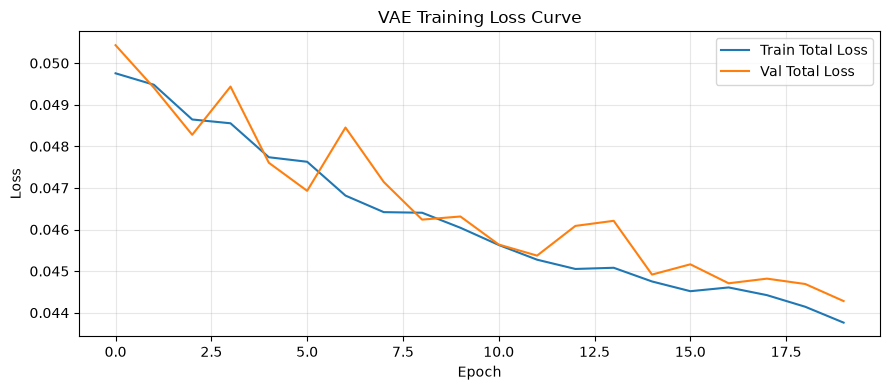

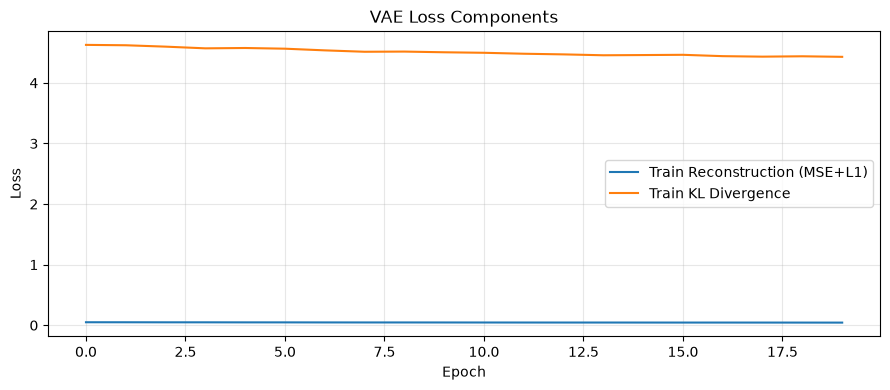

In [14]:
# Cell 11: Plot Loss Curves
plt.figure(figsize=(9, 4))
plt.plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], label="Train Total Loss", linewidth=2)
if val_loader is not None and len(history.get("val_loss", [])) > 0:
    plt.plot(range(1, len(history["val_loss"]) + 1), history["val_loss"], label="Val Total Loss", linewidth=2)
plt.xlabel("Epoch", fontsize=11); plt.ylabel("Loss", fontsize=11)
plt.title("VAE Training Loss Curve", fontsize=13, fontweight="bold")
plt.grid(True, alpha=0.3); plt.legend(fontsize=10); plt.tight_layout()
plt.savefig(RESULTS_DIR / "vae_training_curve.png", dpi=150)
plt.show()

# Loss Components (2 separate subplots with independent scales for clear visualization)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
epochs = range(1, len(history["train_reconstruction"]) + 1)

# Subplot 1: Reconstruction Loss
ax1.plot(epochs, history["train_reconstruction"], color="#1f77b4", linewidth=2, label="Reconstruction (MSE+L1)")
ax1.set_title("Reconstruction Loss (Image Fidelity)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Epoch", fontsize=11); ax1.set_ylabel("Loss", fontsize=11)
ax1.grid(True, alpha=0.3); ax1.legend(loc="upper right", fontsize=10)

# Subplot 2: KL Divergence
ax2.plot(epochs, history["train_kl"], color="#ff7f0e", linewidth=2, label="Raw KL Divergence")
ax2.set_title("KL Divergence (Latent Regularization)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Epoch", fontsize=11); ax2.set_ylabel("KL Divergence", fontsize=11)
ax2.grid(True, alpha=0.3); ax2.legend(loc="upper right", fontsize=10)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "vae_loss_components.png", dpi=150)
plt.show()


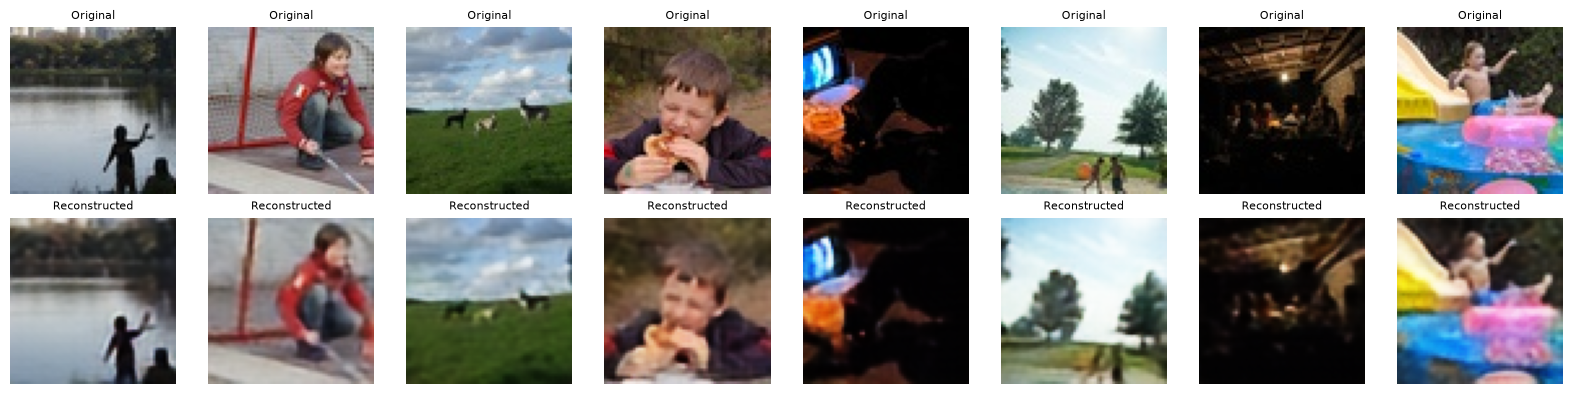

Saved reconstruction grid to: C:\DNN\DNN_Project\results\reconstruction_grid.png


In [15]:
# Cell 12: Real vs. Reconstructed Images
checkpoint = torch.load(best_path, map_location=device, weights_only=False)
vae.load_state_dict(checkpoint["model_state_dict"])
vae.eval()

def denormalize(x):
    return (x * 0.5 + 0.5).clamp(0, 1)

eval_loader = val_loader if val_loader is not None else train_loader
real_batch, _, _ = next(iter(eval_loader))
real_batch = real_batch[:8].to(device)

with torch.no_grad(), torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
    reconstruction, mu, logvar = vae(real_batch, sample=False)

real_images = denormalize(real_batch.cpu())
reconstructed_images = denormalize(reconstruction.float().cpu())

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i in range(real_images.shape[0]):
    axes[0, i].imshow(real_images[i].permute(1, 2, 0))
    axes[0, i].set_title("Original", fontsize=8); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructed_images[i].permute(1, 2, 0))
    axes[1, i].set_title("Reconstructed", fontsize=8); axes[1, i].axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "reconstruction_grid.png", dpi=150)
plt.show()
print("Saved reconstruction grid to:", RESULTS_DIR / "reconstruction_grid.png")

### Step 9: Encode & Cache Latents for Member 2 Handover

In [16]:
# Cell 13: Latent & Token Caching
@torch.no_grad()
def cache_latents(split):
    dataset = FlickrImageDataset(split, image_transform)
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
    out_dir = LATENT_DIR / split
    out_dir.mkdir(parents=True, exist_ok=True)

    latent_batches, token_batches, image_ids, captions = [], [], [], []
    vae.eval()
    
    for images, batch_captions, batch_ids in tqdm(loader, desc=f"Caching {split} latents"):
        images = images.to(device, non_blocking=True)
        mu, _ = vae.encode(images)
        latent_batches.append(mu.cpu().to(torch.float16))
        
        # Pre-tokenize captions into token IDs for Member 2
        tokens = torch.tensor([encode_caption(c) for c in batch_captions], dtype=torch.long)
        token_batches.append(tokens)
        
        image_ids.extend(list(batch_ids))
        captions.extend(list(batch_captions))

    latents = torch.cat(latent_batches, dim=0)
    token_ids = torch.cat(token_batches, dim=0)
    
    torch.save({
        "latents": latents,                    # Shape: [N, 4, 16, 16]
        "token_ids": token_ids,                # Shape: [N, 40]
        "image_ids": image_ids,
        "captions": captions,
        "latent_shape_per_image": list(latents.shape[1:]),
        "source_split": split,
    }, out_dir / "latents.pt")
    
    pd.DataFrame({"image_id": image_ids, "caption": captions}).to_csv(
        out_dir / "latent_index.csv", index=False
    )
    print(f"{split} cached successfully:")
    print(f"  Latents: {tuple(latents.shape)}")
    print(f"  Token IDs: {tuple(token_ids.shape)}")

cache_latents("train")
if (DATA_DIR / "val" / "captions.csv").exists():
    cache_latents("val")

Caching train latents:   0%|          | 0/375 [00:00<?, ?it/s]

train cached successfully:
  Latents: (6000, 4, 16, 16)
  Token IDs: (6000, 40)


Caching val latents:   0%|          | 0/63 [00:00<?, ?it/s]

val cached successfully:
  Latents: (1000, 4, 16, 16)
  Token IDs: (1000, 40)


### Step 10: Export `models/vae.py` & Verify Member 1 Handover Checklist

In [17]:
# Cell 14: Export Python Module and Verification
vae_module_code = '''import torch
import torch.nn as nn

class ConvVAE(nn.Module):
    def __init__(self, latent_channels=4):
        super().__init__()
        self.latent_channels = latent_channels
        
        # Encoder: (3, 64, 64) -> (4, 16, 16)
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1), nn.GroupNorm(8, 64), nn.SiLU(),
            nn.Conv2d(64, 128, 4, 2, 1), nn.GroupNorm(8, 128), nn.SiLU(),
            nn.Conv2d(128, 256, 3, 1, 1), nn.GroupNorm(8, 256), nn.SiLU(),
        )
        self.to_mu = nn.Conv2d(256, latent_channels, 1)
        self.to_logvar = nn.Conv2d(256, latent_channels, 1)

        # Decoder: (4, 16, 16) -> (3, 64, 64)
        self.decoder_input = nn.Sequential(
            nn.Conv2d(latent_channels, 256, 3, 1, 1),
            nn.GroupNorm(8, 256), nn.SiLU(),
        )
        self.decoder = nn.Sequential(
            nn.Conv2d(256, 128, 3, 1, 1), nn.GroupNorm(8, 128), nn.SiLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.GroupNorm(8, 64), nn.SiLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.GroupNorm(8, 32), nn.SiLU(),
            nn.Conv2d(32, 3, 3, 1, 1), nn.Tanh(),
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.to_mu(h)
        logvar = self.to_logvar(h).clamp(-10, 10)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        return mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)

    def decode(self, z):
        return self.decoder(self.decoder_input(z))

    def forward(self, x, sample=True):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar) if sample else mu
        return self.decode(z), mu, logvar
'''

with open(MODEL_DIR / "vae.py", "w", encoding="utf-8") as f:
    f.write(vae_module_code)
(MODEL_DIR / "__init__.py").touch(exist_ok=True)
print("Saved models/vae.py and models/__init__.py for Member 2!")

# Verification checklist
deliverables = [
    TOKENIZER_DIR / "vocab.json",
    TOKENIZER_DIR / "tokenizer_config.json",
    MODEL_DIR / "vae.py",
    CHECKPOINT_DIR / "vae_best.pt",
    RESULTS_DIR / "reconstruction_grid.png",
    RESULTS_DIR / "vae_training_curve.png",
    LATENT_DIR / "train" / "latents.pt",
]

print("\n--- Handover Verification Checklist ---")
all_ready = True
for p in deliverables:
    status = "READY" if p.exists() else "MISSING"
    if not p.exists(): all_ready = False
    print(f"[{status:7s}] {p.name}")

if all_ready:
    print("\nAll Member 1 deliverables are ready for Member 2!")

Saved models/vae.py and models/__init__.py for Member 2!

--- Handover Verification Checklist ---
[READY  ] vocab.json
[READY  ] tokenizer_config.json
[READY  ] vae.py
[READY  ] vae_best.pt
[READY  ] reconstruction_grid.png
[READY  ] vae_training_curve.png
[READY  ] latents.pt

All Member 1 deliverables are ready for Member 2!
